In [2]:
import sys
sys.path.insert(0, '..')

from src import *
import torch
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

Using device: cuda


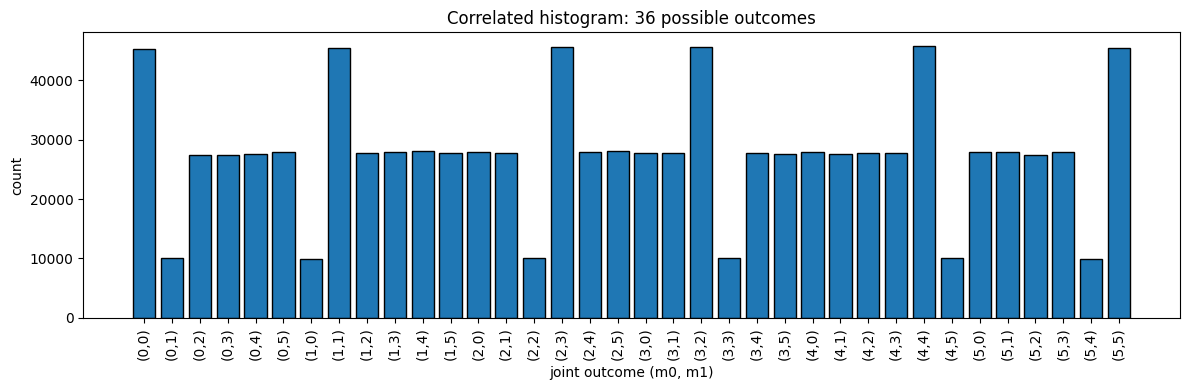

In [2]:
import matplotlib.pyplot as plt
import numpy as np

m = WeakMeasurement(0.5)
state = torch.tensor([1.,0.,0.,1.])/torch.sqrt(torch.tensor([2.]))
state = state.to(dtype=torch.complex128, device=device)
m_seq, _ = m.sample(state[None, :].repeat(1000000, 1))  # m_seq: (N, 2)
# Encode joint outcome (m0, m1) -> m0*6 + m1 in {0..35}
joint = (m_seq[:, 0] * 6 + m_seq[:, 1]).cpu().numpy()
counts, _ = np.histogram(joint, bins=36, range=(0, 36))

fig, ax = plt.subplots(figsize=(12, 4))
labels = [f"({i//6},{i%6})" for i in range(36)]
bars = ax.bar(range(36), counts, edgecolor="black")
ax.set_xlabel("joint outcome (m0, m1)")
ax.set_ylabel("count")
ax.set_xticks(range(36))
ax.set_xticklabels(labels, rotation=90)
ax.set_title("Correlated histogram: 36 possible outcomes")
plt.tight_layout()
plt.show()

In [ ]:
# qr_to_unitary and U @ state via einsum (no UnitaryFeedback)
from src.operator import qr_to_unitary

# 1. A (2, 2) complex -> Q unitary
A = torch.randn(2, 2, dtype=torch.complex128, device=device)
U = qr_to_unitary(A)
print("qr_to_unitary(A) shape:", U.shape)
assert U.shape == (2, 2)

# 2. Unitarity: U† U = I
I_check = U.conj().T @ U
print("U†U ≈ I:", torch.allclose(I_check, torch.eye(2, dtype=U.dtype, device=U.device)))

# 3. Apply U to state: torch.einsum("...ij,...j->...i", U, state)
state = torch.tensor([1.0, 0.0], dtype=torch.complex128, device=device)
out = torch.einsum("ij,j->i", U, state)
print("einsum(U, state) shape:", out.shape)
print("qr_to_unitary and einsum apply OK")

operator(h) shape: torch.Size([2, 2])
U†U ≈ I: True
n=2 U†U ≈ I: True
apply shape: torch.Size([2])
UnitaryFeedback tests OK


## ForwardDiffusion tests

In [17]:
# ForwardDiffusion: single state (use fd_forward so fd is not overwritten by BackwardDiffusion elsewhere)
wm = WeakMeasurement(0.5)
fd_forward = ForwardDiffusion(wm)
n = 2
dim = 2**n
state = torch.randn(dim, dtype=torch.complex128, device=device)
state = state / (state.abs() ** 2).sum().sqrt()
fd_forward.state = state

# step() returns m_seq (n,) only
m_seq = fd_forward.step()
assert m_seq.shape == (n,), f"step() expected ({n},), got {m_seq.shape}"
assert m_seq.dtype == torch.long
assert (m_seq >= 0).all() and (m_seq < 6).all(), "measurement outcomes must be in {0..5}"
print("step() shape:", m_seq.shape, "values in [0,5]:", m_seq.tolist())

# trajectory(T) returns (T, n); state must be set again after step() consumed one
fd_forward.state = state
traj = fd_forward.trajectory(5)
assert traj.shape == (5, n), f"trajectory(5) expected (5, {n}), got {traj.shape}"
assert (traj >= 0).all() and (traj < 6).all()
print("trajectory(5) shape:", traj.shape)
print("ForwardDiffusion single-state OK")

step() shape: torch.Size([2]) values in [0,5]: [4, 3]
trajectory(5) shape: torch.Size([5, 2])
ForwardDiffusion single-state OK


In [18]:
# ForwardDiffusion: batched state (..., 2^n) -> (..., T, n)
B = 4
states = torch.randn(B, dim, dtype=torch.complex128, device=device)
states = states / (states.abs() ** 2).sum(dim=-1, keepdim=True).sqrt()
fd_forward.state = states
traj_batch = fd_forward.trajectory(5)
assert traj_batch.shape == (B, 5, n), f"batched trajectory expected ({B}, 5, {n}), got {traj_batch.shape}"
assert (traj_batch >= 0).all() and (traj_batch < 6).all()
print("batched trajectory shape:", traj_batch.shape)
print("ForwardDiffusion batched OK")

batched trajectory shape: torch.Size([4, 5, 2])
ForwardDiffusion batched OK


In [19]:
# ForwardDiffusion: state must be set before step/trajectory
fd2 = ForwardDiffusion(WeakMeasurement(0.3))
try:
    fd2.step()
except RuntimeError as e:
    assert "state" in str(e).lower()
    print("step() without state raises RuntimeError:", e)
try:
    fd2.trajectory(3)
except RuntimeError as e:
    assert "state" in str(e).lower()
    print("trajectory() without state raises RuntimeError:", e)
print("ForwardDiffusion state-required OK")

step() without state raises RuntimeError: state must be set before step()
trajectory() without state raises RuntimeError: state must be set before trajectory()
ForwardDiffusion state-required OK


In [20]:
# ForwardDiffusion: implementation verification — one step matches Kraus application
wm = WeakMeasurement(0.5)
fd_forward = ForwardDiffusion(wm)
n, dim = 2, 4
state = torch.randn(dim, dtype=torch.complex128, device=device)
state = state / (state.abs() ** 2).sum().sqrt()
fd_forward.state = state
m_one = fd_forward.step()
post_state_from_fd = fd_forward.state
K = wm.operator(m_one.unsqueeze(0)).squeeze(0)  # (dim, dim)
post_from_K = (K @ state)
post_from_K = post_from_K / (post_from_K.abs() ** 2).sum().sqrt()
# Allow global phase difference
dot = (post_state_from_fd.conj() * post_from_K).sum()
assert torch.allclose(dot.abs(), torch.tensor(1.0, dtype=dot.abs().dtype)), "K|psi> should match post-measurement state (up to phase)"
print("Kraus consistency (one step): OK")

Kraus consistency (one step): OK


## Bloch sphere: forward diffusion from |0⟩

Start from |0⟩ (north pole), run forward diffusion with small ε and T steps, visualize final states on the Bloch sphere.

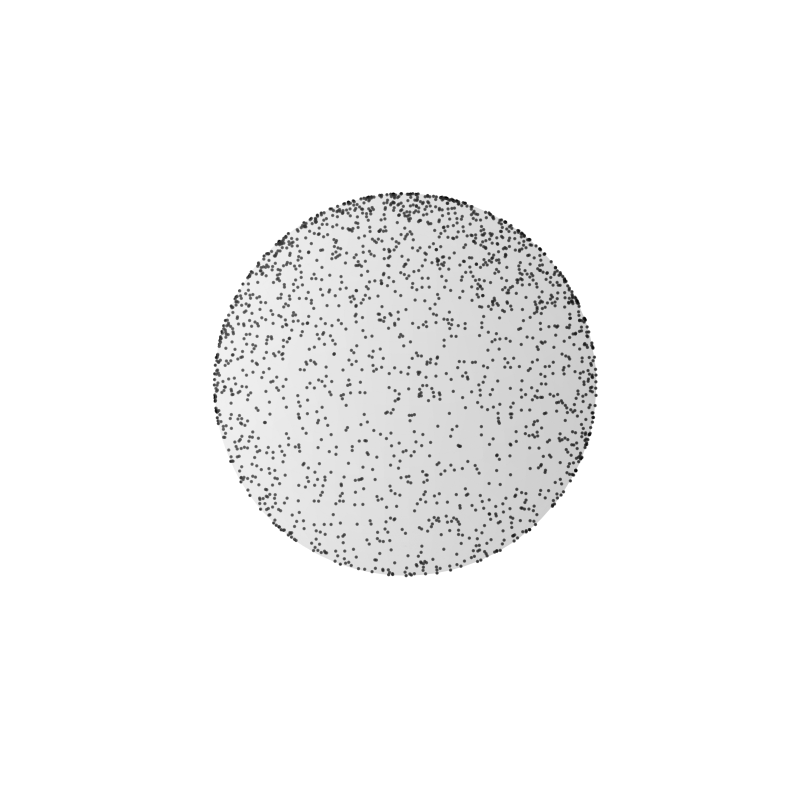

In [5]:
import matplotlib.pyplot as plt
import numpy as np

def bloch_vector_batched(state):
    """Batched: ⟨ψ|σ|ψ⟩ via PAULI. state (..., 2) -> (..., 3)."""
    P = PAULI[1:4].to(state.device)
    return torch.einsum('...i,kij,...j->...k', state.conj(), P, state).real

# Single qubit: n=1, dim=2
n, dim = 1, 2
eps = 0.25
T = 20
n_traj = 2000

# |0⟩ at north pole; batched initial state
psi0 = torch.zeros(dim, dtype=torch.complex128, device=device)
psi0[0] = 1.0
states0 = psi0.unsqueeze(0).expand(n_traj, -1).clone()
wm = WeakMeasurement(eps)
fd = ForwardDiffusion(wm)
fd.state = states0
_ = fd.trajectory(T)  # (n_traj, T, n) measurement sequences; fd.state now holds final states
bloch = bloch_vector_batched(fd.state).cpu().numpy()

# Plot: sphere in empty space, 1:1:1 aspect
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(bloch[:, 0], bloch[:, 1], bloch[:, 2], c="black", s=2, alpha=0.6)

# Semi-transparent Bloch sphere
u = np.linspace(0, 2 * np.pi, 50)
v = np.linspace(0, np.pi, 50)
xs = np.outer(np.cos(u), np.sin(v))
ys = np.outer(np.sin(u), np.sin(v))
zs = np.outer(np.ones(np.size(u)), np.cos(v))
ax.plot_surface(xs, ys, zs, alpha=0.15, color="lightgray")

ax.set_box_aspect([1, 1, 1])
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 1.2)
ax.set_zlim(-1.2, 1.2)
ax.axis("off")
plt.tight_layout()
plt.show()

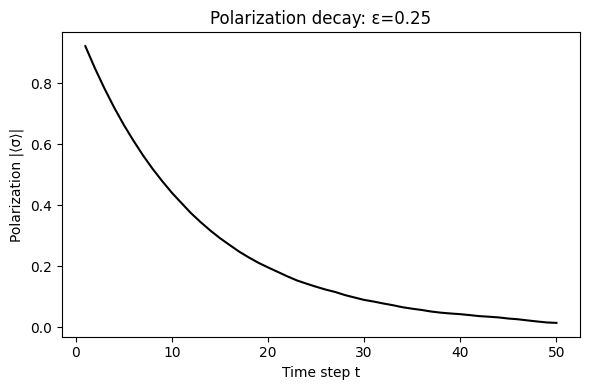

In [16]:
def bloch_vector_batched(state):
    """Batched: ⟨ψ|σ|ψ⟩ via PAULI. state (..., 2) -> (..., 3)."""
    P = PAULI[1:4].to(state.device)
    return torch.einsum('...i,kij,...j->...k', state.conj(), P, state).real

n, dim = 1, 2
eps = 0.25
T_max = 50
n_traj = 50000

psi0 = torch.zeros(dim, dtype=torch.complex128, device=device)
psi0[0] = 1.0
states0 = psi0.unsqueeze(0).expand(n_traj, -1).clone()
wm = WeakMeasurement(eps)
fd = ForwardDiffusion(wm)
fd.state = states0.clone()

polarization = []
for t in range(1, T_max + 1):
    _ = fd.step()  # one step; fd.state evolves in place
    bloch = bloch_vector_batched(fd.state)
    mean_bloch = bloch.mean(dim=0)
    P = torch.linalg.norm(mean_bloch).item()
    polarization.append(P)

plt.figure(figsize=(6, 4))
plt.plot(np.arange(1, T_max + 1), polarization, "k-", lw=1.5)
plt.xlabel("Time step t")
plt.ylabel("Polarization |⟨σ⟩|")
plt.title(f"Polarization decay: ε={eps}")
plt.tight_layout()
plt.show()

In [5]:
# === Train the model and print loss as training proceeds ===
from src import (
    ForwardDiffusion, WeakMeasurement, PolicyModel,
    QuantumDiffusionLoss, DiffusionTrainer,
)

n, dim = 1, 2
eps = 0.8
n_traj, T = 1024, 30
n_epochs = 2000

wm = WeakMeasurement(eps)
fd = ForwardDiffusion(wm)
policy = PolicyModel(n_qubits=n, max_T=T).to(device)
loss_fn = QuantumDiffusionLoss(wm, policy).to(device)
trainer = DiffusionTrainer(fd, policy, loss_fn, lr=1e-3)

# |0⟩ state for n=1
initial_state = torch.tensor([1., 0.], dtype=torch.complex128, device=device)

print(f"Training: n={n}, T={T}, n_traj={n_traj}, n_epochs={n_epochs}")
print("-" * 40)
for epoch in range(n_epochs):
    batch = trainer.collect(n_traj, T, initial_state=initial_state)
    loss = trainer.train_step(batch)
    print(f"Epoch {epoch+1:3d}/{n_epochs}  loss = {loss:.6f}")

Training: n=1, T=30, n_traj=1024, n_epochs=2000
----------------------------------------
Epoch   1/2000  loss = 0.049800
Epoch   2/2000  loss = 0.049372
Epoch   3/2000  loss = 0.049386
Epoch   4/2000  loss = 0.049295
Epoch   5/2000  loss = 0.049141
Epoch   6/2000  loss = 0.049129
Epoch   7/2000  loss = 0.048947
Epoch   8/2000  loss = 0.048879
Epoch   9/2000  loss = 0.048652
Epoch  10/2000  loss = 0.048826
Epoch  11/2000  loss = 0.048507
Epoch  12/2000  loss = 0.048287
Epoch  13/2000  loss = 0.048217
Epoch  14/2000  loss = 0.048017
Epoch  15/2000  loss = 0.047894
Epoch  16/2000  loss = 0.047836
Epoch  17/2000  loss = 0.047684
Epoch  18/2000  loss = 0.047663
Epoch  19/2000  loss = 0.047397
Epoch  20/2000  loss = 0.047402
Epoch  21/2000  loss = 0.047207
Epoch  22/2000  loss = 0.047289
Epoch  23/2000  loss = 0.047066
Epoch  24/2000  loss = 0.046802
Epoch  25/2000  loss = 0.046761
Epoch  26/2000  loss = 0.046800
Epoch  27/2000  loss = 0.046601
Epoch  28/2000  loss = 0.046536
Epoch  29/2000 

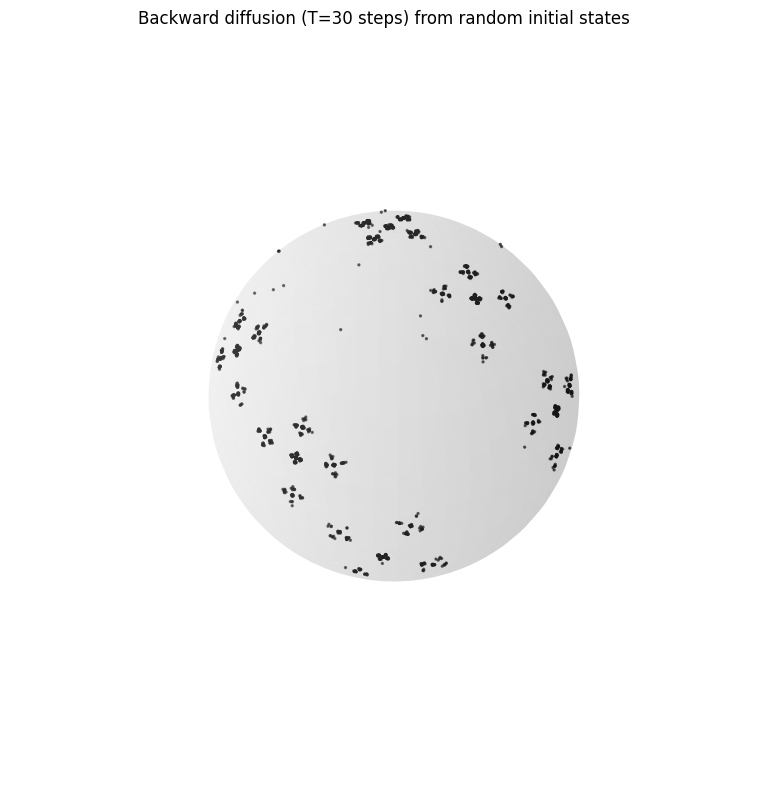

In [6]:
# === Backward diffusion with trained policy: plot state distribution on Bloch sphere ===
# Requires: wm, policy, fd, n, dim, T from training cell above; PAULI from first cell
import matplotlib.pyplot as plt
import numpy as np

def bloch_vector_batched(state):
    """Batched: ⟨ψ|σ|ψ⟩ via PAULI. state (..., 2) -> (..., 3)."""
    P = PAULI[1:4].to(state.device)
    return torch.einsum("...i,kij,...j->...k", state.conj(), P, state).real

T_bwd = T  # use same T as training
n_traj_bwd = 2000

# Forward trajectory to condition the policy (e.g. from |0⟩)
fd.state = initial_state.unsqueeze(0).expand(n_traj_bwd, -1).clone()
m_forward_seqs = fd.trajectory(T_bwd)  # (n_traj_bwd, T, n)

# Backward diffusion: start from random pure states
bd = BackwardDiffusion(wm, policy)
bd.forward_trajectory = m_forward_seqs
real = torch.randn(n_traj_bwd, dim, dtype=torch.float64, device=device)
imag = torch.randn(n_traj_bwd, dim, dtype=torch.float64, device=device)
states0 = (real + 1j * imag).to(torch.complex128)
states0 = states0 / (states0.abs()**2).sum(-1, keepdim=True).sqrt()
bd.state = states0

_ = bd.trajectory(T_bwd)  # bd.state now holds final (recovered) states
bloch = bloch_vector_batched(bd.state).cpu().numpy()

# Plot on Bloch sphere
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(bloch[:, 0], bloch[:, 1], bloch[:, 2], c="black", s=2, alpha=0.6)
u = np.linspace(0, 2 * np.pi, 50)
v = np.linspace(0, np.pi, 50)
xs = np.outer(np.cos(u), np.sin(v))
ys = np.outer(np.sin(u), np.sin(v))
zs = np.outer(np.ones(np.size(u)), np.cos(v))
ax.plot_surface(xs, ys, zs, alpha=0.15, color="lightgray")
ax.set_box_aspect([1, 1, 1])
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 1.2)
ax.set_zlim(-1.2, 1.2)
ax.axis("off")
ax.set_title(f"Backward diffusion (T={T_bwd} steps) from random initial states")
plt.tight_layout()
plt.show()